# 04 — Baseline Real Only: log-mel + logistic regression
**Câu hỏi tuần 1:** pipeline dữ liệu thật có chạy đúng và dự đoán được cả hai lớp không?
Chưa đo lợi ích DSP-E/S. Đầu vào: segment train/validation từ notebook 03.
Đầu ra: 80 features/event, scaler, class weights, mô hình, bảng chọn lambda,
predictions, metrics và confusion matrices. **Không có test features hoặc test score.**
Thuật toán nằm trực tiếp trong các ô: STFT → mel → mean/std → scaler → logistic.
Chạy Restart Kernel → Run All. Logistic nhỏ chạy CPU, không cần GPU/Colab.

In [1]:
from pathlib import Path
from datetime import datetime, timezone
from collections import Counter, defaultdict
import csv, hashlib, json, platform, sys, time, uuid
import importlib.metadata as metadata
import numpy as np
from IPython.display import display, Markdown

PROJECT_PATH = ""  # Chỉ điền thư mục gốc nếu kernel mở ngoài dự án.
print("Kernel:", sys.executable, "\nCWD:", Path.cwd())
if PROJECT_PATH and sys.platform != "win32" and ":" in PROJECT_PATH:
    raise ValueError("Đang dùng kernel Linux với đường dẫn Windows. Chọn kernel DSP local.")
candidates = [Path(PROJECT_PATH)] if PROJECT_PATH else [Path.cwd(), *Path.cwd().parents]
ROOT = next((p.resolve() for p in candidates if (p / 'requirements-dsp.txt').is_file() and (p / 'dsp/notebooks').is_dir()), None)
if ROOT is None:
    raise FileNotFoundError("Điền PROJECT_PATH là thư mục chứa requirements-dsp.txt; xem README.md")
STARTED = time.perf_counter()

def read_csv(path):
    with path.open(encoding='utf-8-sig', newline='') as f:
        return list(csv.DictReader(f))

def write_csv(path, rows, fields=None):
    with path.open('w', encoding='utf-8', newline='') as f:
        w = csv.DictWriter(f, fieldnames=fields or list(rows[0]))
        w.writeheader()
        w.writerows(rows)

def sha256(path):
    h = hashlib.sha256()
    with path.open('rb') as f:
        for block in iter(lambda: f.read(1024 * 1024), b''):
            h.update(block)
    return h.hexdigest()

def verify(summary):
    for relative, expected in summary['output_sha256'].items():
        assert sha256(ROOT / relative) == expected, f"Checksum sai: {relative}"

def save_summary(path, summary, outputs):
    summary.update(created_at_utc=datetime.now(timezone.utc).isoformat(),
                   python=sys.version, executable=sys.executable, platform=platform.platform(),
                   versions={n: metadata.version(n) for n in ['numpy','scipy','matplotlib','ipykernel','nbformat']},
                   elapsed_seconds=time.perf_counter()-STARTED,
                   output_sha256={str(p.relative_to(ROOT)).replace('\\','/'): sha256(p) for p in outputs})
    path.write_text(json.dumps(summary, ensure_ascii=False, indent=2), encoding='utf-8')
    print("Đã lưu:", path.relative_to(ROOT))

def snapshot(name, destination):
    import nbformat
    nb = nbformat.read(ROOT / 'dsp/notebooks' / name, as_version=4)
    for cell in nb.cells:
        if cell.cell_type == 'code':
            cell.outputs, cell.execution_count = [], None
    nbformat.write(nb, destination)

Kernel: [home]\AppData\Local\Programs\Python\Python311\python.exe 
CWD: d:\VGU-27\Digital Signal Processing\dsp\notebooks


## 1. Tham số frontend và optimizer
Theo proposal: 40 bands, Hann 25 ms, hop 10 ms, floor power 1e-10, natural log;
chỉ pool frame có tâm thuộc valid region. Chọn bổ sung FFT=256, periodic Hann,
không center-pad STFT, HTK mel scale với tam giác chuẩn hóa diện tích.
Power một phía = |FFT|² / tổng(window²); không nhân đôi interior bins, không gọi đây là PSD chuẩn.
Ghi quy ước để các điều kiện sau dùng cùng frontend, không phải để giống mặc định thư viện khác.
Lambda grid/threshold/tolerance theo proposal. Tie chính xác macro-F1 chọn lambda lớn hơn.
`ftol=0` tránh dừng chỉ vì loss thay đổi ít khi gradient chưa đạt yêu cầu.

In [2]:
from scipy.signal.windows import hann
from scipy.optimize import minimize, check_grad
from scipy.special import expit
import matplotlib.pyplot as plt

SEGMENT_ID = 'segments_20261026T184202Z_8416ef'
N_MELS, FFT_SIZE = 40, 256
WINDOW_MS, HOP_MS = 25, 10
POWER_FLOOR = 1e-10
PENALTIES = [1e-4,1e-3,1e-2,1e-1,1.0]
GRAD_TOL, MAX_ITER = 1e-6, 1000
segment_path = ROOT/'dsp/outputs/reports'/SEGMENT_ID/'segment_summary.json'
segment_summary = json.loads(segment_path.read_text(encoding='utf-8'))
verify(segment_summary)
source = ROOT/'dsp/data/processed'/SEGMENT_ID
rows = read_csv(source/'segments.csv')
waveforms = np.load(source/'waveforms.npy',mmap_mode='r')
FS = segment_summary['preprocessing']['fs_hz']
WINDOW = int(FS*WINDOW_MS/1000)
HOP = int(FS*HOP_MS/1000)
assert len(rows)==len(waveforms) and waveforms.shape[1]==2*FS
assert [int(r['row_index']) for r in rows]==list(range(len(rows)))
assert {r['split'] for r in rows}=={'train','validation'}
train_mask = np.array([r['split']=='train' for r in rows])
val_mask = ~train_mask
y = np.array([{'Normal':0,'Wheeze':1}[r['label']] for r in rows])
assert {r['subject_id'] for r in rows if r['split']=='train'}.isdisjoint(
       {r['subject_id'] for r in rows if r['split']=='validation'})
print('Train / validation:',train_mask.sum(),val_mask.sum())

Train / validation: 4422 1189


## 2. Tạo mel filters và tính đặc trưng
Mỗi frame dài 200 sample; hop 80 sample; FFT zero-pad lên 256. Tâm frame đầu ở sample 100.
40 giá trị trung bình + 40 độ lệch chuẩn (ddof=0) → vector 80 chiều.
Padding vẫn có thể ảnh hưởng frame sát biên, dù frame có tâm trong padding không được pool.
Vì vậy bảng padding trong notebook 03 vẫn cần theo dõi.

In [3]:
def make_mel_bank(fs, n_fft, n_mels):
    """HTK mel spacing, tam giác diện tích 1 (đơn vị nghịch đảo Hz)."""
    max_mel = 2595*np.log10(1+(fs/2)/700)
    edges = 700*(10**(np.linspace(0,max_mel,n_mels+2)/2595)-1)
    frequencies = np.fft.rfftfreq(n_fft,1/fs)
    bank = np.zeros((n_mels,len(frequencies)))
    for m in range(n_mels):
        left,center,right = edges[m:m+3]
        bank[m] = np.maximum(0,np.minimum((frequencies-left)/(center-left),(right-frequencies)/(right-center)))
        bank[m] *= 2/(right-left)
    assert np.all(bank.sum(axis=1)>0), 'FFT quá nhỏ làm mất mel band'
    return bank, edges

mel_bank, mel_edges = make_mel_bank(FS,FFT_SIZE,N_MELS)
window = hann(WINDOW,sym=False)

def log_mel_features(signal, valid_start, valid_end):
    """Trả vector 80 chiều và log-mel/frame mask để vẽ; sample bounds là [start,end)."""
    frames = np.lib.stride_tricks.sliding_window_view(np.asarray(signal,dtype=float),WINDOW)[::HOP]
    centers = np.arange(len(frames))*HOP + WINDOW/2
    valid = (centers>=valid_start)&(centers<valid_end)
    assert valid.any(), 'Không có frame tâm trong valid region; xem crop trước khi training'
    spectrum = np.fft.rfft(frames*window,n=FFT_SIZE,axis=1)
    power = abs(spectrum)**2/np.sum(window**2)
    log_mel = np.log(np.maximum(power@mel_bank.T,POWER_FLOOR))
    kept = log_mel[valid]
    features = np.concatenate([kept.mean(axis=0),kept.std(axis=0,ddof=0)])
    return features, log_mel, valid, centers

## 3. Probe frontend
Tone 1 kHz phải đạt đỉnh ở band chứa 1 kHz. Frame pooling phải bỏ phần padding xa biên.
Probe im lặng phải hữu hạn nhờ floor; không đồng nghĩa im lặng được nhận vào dữ liệu thật.

In [4]:
t = np.arange(16000)/FS
tone = np.sin(2*np.pi*1000*t)
f, lm, mask, centers = log_mel_features(tone,0,16000)
peak_band = int(np.argmax(lm.mean(axis=0)))
assert mel_edges[peak_band] < 1000 < mel_edges[peak_band+2]
assert centers[0]==100 and len(f)==80 and np.isfinite(f).all()
zeros, _, _, _ = log_mel_features(np.zeros(16000),0,16000)
assert np.allclose(zeros[:40],np.log(POWER_FLOOR)) and np.allclose(zeros[40:],0)
altered = tone.copy()
altered[:1000],altered[-1000:] = 100,-100
assert np.allclose(log_mel_features(tone,5000,11000)[0],log_mel_features(altered,5000,11000)[0])
print('PASS: tone band, log floor, frame centers và valid pooling.')

PASS: tone band, log floor, frame centers và valid pooling.


## 4. Tính features và chuẩn hóa bằng train
Validation chỉ biến đổi bằng scaler train. Class weights tính một lần từ real train:
`n / (2*n_class)`; trung bình trọng số trên real train bằng 1. Không cập nhật lại khi thêm synthetic.

In [5]:
feature_start = time.perf_counter()
features = np.empty((len(rows),80),dtype=float)
frame_counts = []
for i,r in enumerate(rows):
    f,lm,valid,centers = log_mel_features(waveforms[i],int(r['valid_start_sample']),int(r['valid_end_sample']))
    features[i] = f
    frame_counts.append(int(valid.sum()))
assert np.isfinite(features).all()
feature_seconds = time.perf_counter()-feature_start
scaler_mean = features[train_mask].mean(axis=0)
scaler_std_raw = features[train_mask].std(axis=0,ddof=0)
constant_features = scaler_std_raw < 1e-12  # numerical division guard, không feature selection
scaler_std = np.where(constant_features,1.0,scaler_std_raw)
Z = (features-scaler_mean)/scaler_std
class_counts = np.bincount(y[train_mask],minlength=2)
assert np.all(class_counts>0)
class_weights = class_counts.sum()/(2*class_counts)
weights = class_weights[y[train_mask]]
assert np.isclose(weights.mean(),1)
assert np.max(np.abs(Z[train_mask].mean(axis=0))) < 1e-8
print('Feature shape:',features.shape,'; extraction seconds:',round(feature_seconds,2))
print('Real train counts:',class_counts,'; frozen weights:',class_weights)
print('Valid frame min/median/max:',np.quantile(frame_counts,[0,.5,1]))

Feature shape: (5611, 80) ; extraction seconds: 4.61
Real train counts: [4094  328] ; frozen weights: [0.[subject_id] 6.[subject_id]]
Valid frame min/median/max: [ 13. 128. 198.]


## 5. Hàm loss và solver
Loss = Σ(wᵢ × logistic_lossᵢ)/Σwᵢ + λ/2 × ||coef||²; intercept không phạt.
Chia cho tổng weights giúp penalty có cùng định nghĩa khi thêm dữ liệu.
`logaddexp` và `expit` tránh overflow. Hàm trả cả loss và gradient để L-BFGS-B hội tụ ổn định.
Các điều kiện augmentation sau phải giữ scaler, weights, lambda và solver này.

In [6]:
def logistic_loss_and_gradient(theta, X, labels, sample_weights, penalty):
    """Weighted average cross-entropy + L2 của coefficients; intercept ở phần tử cuối."""
    coef, intercept = theta[:-1], theta[-1]
    score = X@coef + intercept
    normalized_weights = sample_weights/sample_weights.sum()
    loss = np.sum(normalized_weights*(np.logaddexp(0,score)-labels*score)) + penalty/2*np.dot(coef,coef)
    residual = normalized_weights*(expit(score)-labels)
    gradient = np.r_[X.T@residual+penalty*coef,residual.sum()]
    return float(loss), gradient

def fit_logistic(X, labels, sample_weights, penalty):
    """Fit deterministic từ zero; không stochastic minibatches hoặc GPU."""
    start = time.perf_counter()
    result = minimize(logistic_loss_and_gradient,np.zeros(X.shape[1]+1),
        args=(X,labels,sample_weights,penalty),jac=True,method='L-BFGS-B',
        options=dict(gtol=GRAD_TOL,ftol=0.0,maxiter=MAX_ITER,maxls=50))
    gradient_max = float(np.max(abs(result.jac)))
    assert result.success and gradient_max<=GRAD_TOL, f'Không hội tụ: {result.message}; grad={gradient_max}'
    return result, time.perf_counter()-start

## 6. Kiểm gradient và chuẩn hóa loss
Gradient phân tích được đối chiếu finite differences trên một bài toán nhỏ độc lập.
Nhân đôi mọi dòng phải giữ nguyên weighted-average loss và gradient; intercept không chịu L2.

In [7]:
xp = np.array([[1.,2.],[-1.,0.],[0.,-2.],[.5,.25]])
yp = np.array([1,0,0,1])
wp = np.array([1.,2.,1.,2.])
theta = np.array([.2,-.3,.4])
err = check_grad(lambda q:logistic_loss_and_gradient(q,xp,yp,wp,.1)[0],
                 lambda q:logistic_loss_and_gradient(q,xp,yp,wp,.1)[1],theta)
assert err < 1e-6
loss, grad = logistic_loss_and_gradient(theta,xp,yp,wp,.1)
loss2, grad2 = logistic_loss_and_gradient(theta,np.tile(xp,(2,1)),np.tile(yp,2),np.tile(wp,2),.1)
assert np.isclose(loss,loss2) and np.allclose(grad,grad2)
no_penalty = logistic_loss_and_gradient(theta,xp,yp,wp,0)[1]
assert np.isclose(grad[-1],no_penalty[-1])
assert np.allclose(grad[:-1]-no_penalty[:-1],.1*theta[:-1])
print('PASS gradient finite difference:',err,'; loss normalization; intercept unpenalized.')

PASS gradient finite difference: 1.1429988135001362e-08 ; loss normalization; intercept unpenalized.


## 7. Metrics nhị phân dễ đọc
Confusion matrix: hàng = thật, cột = dự đoán, thứ tự Normal/Wheeze.
Sensitivity = recall Wheeze; specificity = recall Normal. Undefined division trả 0 theo proposal.
Macro-F1 cân hai lớp nhưng không cân số event mỗi người.

In [8]:
def evaluate(labels, predictions):
    matrix = np.zeros((2,2),dtype=int)
    np.add.at(matrix,(labels,predictions),1)
    per_class = []
    for c,name in enumerate(['Normal','Wheeze']):
        tp = int(matrix[c,c])
        fp = int(matrix[:,c].sum()-tp)
        fn = int(matrix[c,:].sum()-tp)
        precision = tp/(tp+fp) if tp+fp else 0.0
        recall = tp/(tp+fn) if tp+fn else 0.0
        f1 = 2*tp/(2*tp+fp+fn) if 2*tp+fp+fn else 0.0
        per_class.append(dict(label=name,precision=precision,recall=recall,f1=f1,support=int(matrix[c].sum())))
    return dict(macro_f1=float(np.mean([p['f1'] for p in per_class])),
        sensitivity=per_class[1]['recall'],specificity=per_class[0]['recall'],
        confusion_matrix=matrix.tolist(),per_class=per_class,
        predicted_classes=sorted(np.unique(predictions).tolist()))

probe_metrics = evaluate(np.array([0,0,1,1]),np.array([0,1,0,1]))
assert probe_metrics['macro_f1']==probe_metrics['sensitivity']==probe_metrics['specificity']==.5
assert np.isclose(evaluate(np.array([0,0,1,1]),np.zeros(4,dtype=int))['macro_f1'],1/3)
print('PASS: metrics trên confusion matrices biết trước.')

PASS: metrics trên confusion matrices biết trước.


## 8. Chọn lambda một lần trên validation Real Only
Chỉ fit trên train. Lưu mọi điểm trong grid; không thay split hoặc threshold sau khi xem điểm.
Đây là development score dùng chọn lambda, không phải ước lượng độc lập trên test.

In [9]:
grid, fitted = [], {}
for penalty in PENALTIES:
    result, seconds = fit_logistic(Z[train_mask],y[train_mask],weights,penalty)
    prediction = (Z[val_mask]@result.x[:-1]+result.x[-1]>=0).astype(int)
    metrics = evaluate(y[val_mask],prediction)
    grid.append(dict(penalty=penalty,validation_macro_f1=metrics['macro_f1'],
        iterations=int(result.nit),gradient_max=float(np.max(abs(result.jac))),seconds=seconds,
        converged=bool(result.success),message=str(result.message)))
    fitted[penalty]=result.x
best = max(grid,key=lambda r:(r['validation_macro_f1'],r['penalty']))
selected_penalty = best['penalty']
theta = fitted[selected_penalty]
probabilities = expit(Z@theta[:-1]+theta[-1])
predictions = (probabilities>=.5).astype(int)
metrics_by_split = {part:evaluate(y[mask],predictions[mask]) for part,mask in [('train',train_mask),('validation',val_mask)]}
display(grid)
print('Lambda chọn:',selected_penalty)
for part,metrics in metrics_by_split.items():
    print(part, 'macro-F1:',round(metrics['macro_f1'],6),'sensitivity:',round(metrics['sensitivity'],6),
          'specificity:',round(metrics['specificity'],6),'predicted classes:',metrics['predicted_classes'])
    if len(metrics['predicted_classes'])<2: print('CẢNH BÁO: classifier collapse; ghi vấn đề, không tự chọn split khác.')

[{'penalty': 0.0001,
  'validation_macro_f1': 0.6761321075927818,
  'iterations': 559,
  'gradient_max': 8.369444011108455e-07,
  'seconds': 0.6779133000527509,
  'converged': True,
  'message': 'CONVERGENCE: NORM OF PROJECTED GRADIENT <= PGTOL'},
 {'penalty': 0.001,
  'validation_macro_f1': 0.6728471378939684,
  'iterations': 242,
  'gradient_max': 8.845698278027686e-07,
  'seconds': 0.2618891000165604,
  'converged': True,
  'message': 'CONVERGENCE: NORM OF PROJECTED GRADIENT <= PGTOL'},
 {'penalty': 0.01,
  'validation_macro_f1': 0.665717068845842,
  'iterations': 89,
  'gradient_max': 9.261183030056543e-07,
  'seconds': 0.0945122999837622,
  'converged': True,
  'message': 'CONVERGENCE: NORM OF PROJECTED GRADIENT <= PGTOL'},
 {'penalty': 0.1,
  'validation_macro_f1': 0.6561953906727698,
  'iterations': 34,
  'gradient_max': 9.68301679143968e-07,
  'seconds': 0.04555199999595061,
  'converged': True,
  'message': 'CONVERGENCE: NORM OF PROJECTED GRADIENT <= PGTOL'},
 {'penalty': 1.0,

Lambda chọn: 0.0001
train macro-F1: 0.649927 sensitivity: 0.771341 specificity: 0.832926 predicted classes: [0, 1]
validation macro-F1: 0.676132 sensitivity: 0.790323 specificity: 0.814085 predicted classes: [0, 1]


## 9. Hình và lưu kết quả có lineage
Predictions có event/subject/split để sau này tính uncertainty theo người.
Baseline deterministic chỉ fit một lần mỗi lambda; không tạo ba lần chạy giống nhau để báo std giả.
Ba repetitions của tuần 3 đo biến thiên augmentation, không phải điều kiện hoàn thành tuần 1.

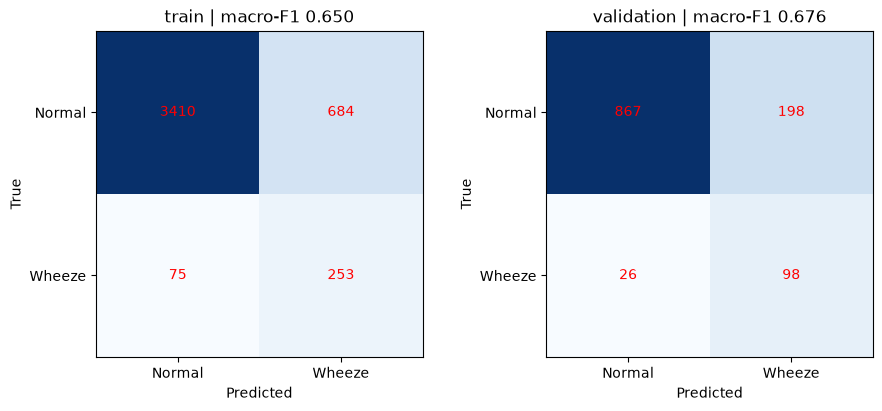

In [10]:
BASELINE_ID = 'baseline_' + datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%SZ') + '_' + uuid.uuid4().hex[:6]
out = ROOT/'dsp/outputs/runs'/BASELINE_ID
report = ROOT/'dsp/outputs/reports'/BASELINE_ID
out.mkdir(parents=True,exist_ok=False)
report.mkdir(parents=True,exist_ok=False)
np.save(out/'features.npy',features)
np.savez(out/'model.npz',coef=theta[:-1],intercept=theta[-1],scaler_mean=scaler_mean,
         scaler_std=scaler_std,class_weights=class_weights,penalty=selected_penalty)
prediction_rows = [dict(event_id=r['event_id'],subject_id=r['subject_id'],recording_id=r['recording_id'],
    split=r['split'],true_label=r['label'],predicted_label=['Normal','Wheeze'][predictions[i]],
    wheeze_probability=float(probabilities[i]),row_index=i,valid_frames=frame_counts[i]) for i,r in enumerate(rows)]
write_csv(out/'predictions.csv',prediction_rows)
write_csv(report/'regularization_grid.csv',grid)
metric_rows = [dict(split=part,**r) for part,m in metrics_by_split.items() for r in m['per_class']]
write_csv(report/'per_class_metrics.csv',metric_rows)
fig,axes=plt.subplots(1,2,figsize=(9,4),layout='constrained')
for ax,(part,m) in zip(axes,metrics_by_split.items()):
    matrix=np.array(m['confusion_matrix'])
    ax.imshow(matrix,cmap='Blues')
    for i in range(2):
        for j in range(2): ax.text(j,i,str(matrix[i,j]),ha='center',va='center',color='red')
    ax.set(xticks=[0,1],yticks=[0,1],xticklabels=['Normal','Wheeze'],yticklabels=['Normal','Wheeze'],
           xlabel='Predicted',ylabel='True',title=part+' | macro-F1 '+format(m['macro_f1'],'.3f'))
fig.savefig(report/'confusion_matrices.png',dpi=140)
plt.show()

## 10. Kiểm nạp lại mô hình và freeze cấu hình
Không pickle, không framework: `model.npz` chỉ chứa các mảng số. Muốn dự đoán lại:
feature → trừ mean/chia std đã lưu → nhân coef + intercept → sigmoid → ngưỡng 0.5.
File JSON ghi đầy đủ frontend và optimizer; notebook sau đọc artifacts, không import notebook này.

In [11]:
with np.load(out/'model.npz') as saved:
    restored=expit(((features-saved['scaler_mean'])/saved['scaler_std'])@saved['coef']+saved['intercept'])
assert np.array_equal((restored>=.5).astype(int),predictions)
assert np.allclose(restored,probabilities,rtol=0,atol=1e-14)
snapshot('04_baseline_real_only.ipynb',report/'notebook_source.ipynb')
config = dict(fs_hz=FS,n_mels=N_MELS,fft_size=FFT_SIZE,window_samples=WINDOW,hop_samples=HOP,
    hann='periodic',frame_centering='no STFT padding; center=start+window/2',
    mel='HTK spacing; triangle area normalization 2/(right-left)',power='abs(rfft)^2/sum(window^2); no bin doubling',
    power_floor=POWER_FLOOR,log='natural',pool='mean/std ddof=0; valid centers only',
    scaler='real train only; std < 1e-12 -> 1',class_weights=class_weights.tolist(),
    selected_penalty=selected_penalty,penalty_grid=PENALTIES,tie_break='larger penalty',threshold=.5,
    loss='sum(w*logistic_loss)/sum(w) + lambda/2*||coef||^2; intercept unpenalized',
    solver='L-BFGS-B, zero initialization',gtol=GRAD_TOL,ftol=0,maxiter=MAX_ITER,maxls=50)
summary = dict(run_id=BASELINE_ID,segment_id=SEGMENT_ID,segment_summary_sha256=sha256(segment_path),
    split_id=segment_summary['split_id'],config=config,metrics=metrics_by_split,feature_seconds=feature_seconds,
    total_solver_seconds=sum(g['seconds'] for g in grid),gradient_probe_error=err,
    reload_predictions_identical=True,test_audio_read=False,test_evaluated=False,
    validation_used_for_penalty_selection=True,augmentation_tested=False,
    memory_note='CPU; RSS/peak memory not measured. Waveforms loaded using memory map.')
save_summary(report/'baseline_summary.json',summary,list(out.glob('*'))+list(report.glob('*.csv'))+
             [report/'notebook_source.ipynb',report/'confusion_matrices.png'])
val=metrics_by_split['validation']
(report/'BAO_CAO.md').write_text('# Real Only development baseline\n\n'+
    'Lambda: '+str(selected_penalty)+'. Validation macro-F1: '+format(val['macro_f1'],'.4f')+
    '; sensitivity: '+format(val['sensitivity'],'.4f')+'; specificity: '+format(val['specificity'],'.4f')+
    '.\n\nXem regularization_grid.csv, per_class_metrics.csv và predictions.csv trong run. '+
    'Tất cả 5 fits đạt gradient tolerance; nạp lại mô hình giữ nguyên prediction.\n\n'+
    'Validation đã dùng chọn lambda, chưa phải test độc lập. Không kết luận hiệu quả DSP-E/S. '+
    'Giữ nguyên split; chưa có augmentation variance hoặc clinical validation.\n',encoding='utf-8')
print('BASELINE_ID =',repr(BASELINE_ID))

Đã lưu: dsp\outputs\reports\baseline_20261028T113029Z_2d31ba\baseline_summary.json
BASELINE_ID = 'baseline_20261028T113029Z_2d31ba'
